# Redes Neurais Artificiais — Da Teoria à Prática com PyTorch

**Aula completa:** história, conceitos fundamentais, aplicações e um projeto end-to-end.

## Roteiro

1. 📜 História das redes neurais
2. 🧠 Conceitos fundamentais (neurônio, ativação, backpropagation)
3. 🌍 Aplicações no mundo real
4. 📥 Aquisição de dados
5. 🔍 EDA — Análise Exploratória completa
6. ⚙️ Pré-processamento
7. 🏗️ Construção do modelo em PyTorch
8. 🏋️ Treinamento
9. 📊 Avaliação
10. 💾 Salvando e recarregando o modelo

## 📜 1. História das Redes Neurais

### 1943 — O neurônio de McCulloch e Pitts
Primeiro modelo matemático do neurônio: soma as entradas ponderadas e dispara se o limiar for atingido. Conseguia implementar funções lógicas (AND, OR, NOT).

### 1958 — O Perceptron de Rosenblatt
Primeiro neurônio artificial **capaz de aprender**, ajustando seus pesos automaticamente. Rodava no Mark-1 da IBM e causou grande euforia na imprensa.

### 1969 — O \"Inverno da IA\"
Minsky e Papert, no livro *Perceptrons*, mostraram que o perceptron de uma camada não resolve problemas **não linearmente separáveis** como o XOR. O financiamento secou — começou o inverno da IA.

### 1986 — Backpropagation popularizado
Rumelhart, Hinton e Williams popularizaram o algoritmo de backpropagation, que permitiu treinar **camadas ocultas** — as MLPs resolveram o XOR e o interesse voltou.

### 1989–1998 — CNNs e o LeNet
Yann LeCun desenvolveu as redes convolucionais; o **LeNet-5** lia cheques bancários com alta precisão, uma das primeiras aplicações industriais de deep learning.

### 2012 — A Revolução do Deep Learning
A **AlexNet** venceu o ImageNet reduzindo o erro de ~26% para ~15%. O uso de **GPUs** tornou viável treinar redes profundas — começou a era moderna.

### 2017–hoje — Transformers e IA generativa
O artigo *Attention Is All You Need* introduziu os Transformers, base de modelos como GPT, BERT e Claude — a era da IA generativa.

## 🧠 2. Conceitos Fundamentais

### O neurônio artificial
Recebe entradas x1..xn, cada uma multiplicada por um peso wi, somadas a um viés b, passando por uma função de ativação:

- `z = w1*x1 + w2*x2 + ... + wn*xn + b`
- `a = sigma(z)`

- **Pesos**: medem a importância de cada entrada
- **Viés**: desloca o limiar de ativação
- **Ativação**: introduz não-linearidade na rede

### Funções de ativação mais comuns

| Função | Fórmula | Uso típico |
|---|---|---|
| ReLU | max(0, z) | Camadas ocultas |
| Sigmoid | 1/(1+e^-z) | Saída binária |
| Softmax | Normaliza exponenciais | Saída multiclasse |

### Como a rede aprende: backpropagation

1. **Forward pass**: os dados atravessam a rede e produzem uma previsão
2. **Função de perda**: mede o erro entre previsão e valor real
3. **Backward pass**: calcula os gradientes do erro em relação a cada peso, pela regra da cadeia
4. **Atualização pelo otimizador**: ajusta os pesos na direção que reduz o erro

`w <- w - eta * dL/dw`

### Hiperparâmetros importantes

- **Época**: uma passada completa pelo conjunto de treino
- **Batch size**: número de amostras processadas antes de atualizar os pesos
- **Learning rate**: tamanho do passo na atualização dos pesos

## 🏗️ Arquitetura da Rede — Perceptron Multicamadas (MLP)

Nossa rede tem **3 camadas ocultas**. Cada círculo é um neurônio, cada linha uma conexão com peso treinável:

- **Entradas**: 30 features do exame
- **Camadas ocultas**: extraem padrões cada vez mais abstratos
- **Saída**: 1 neurônio → probabilidade do diagnóstico

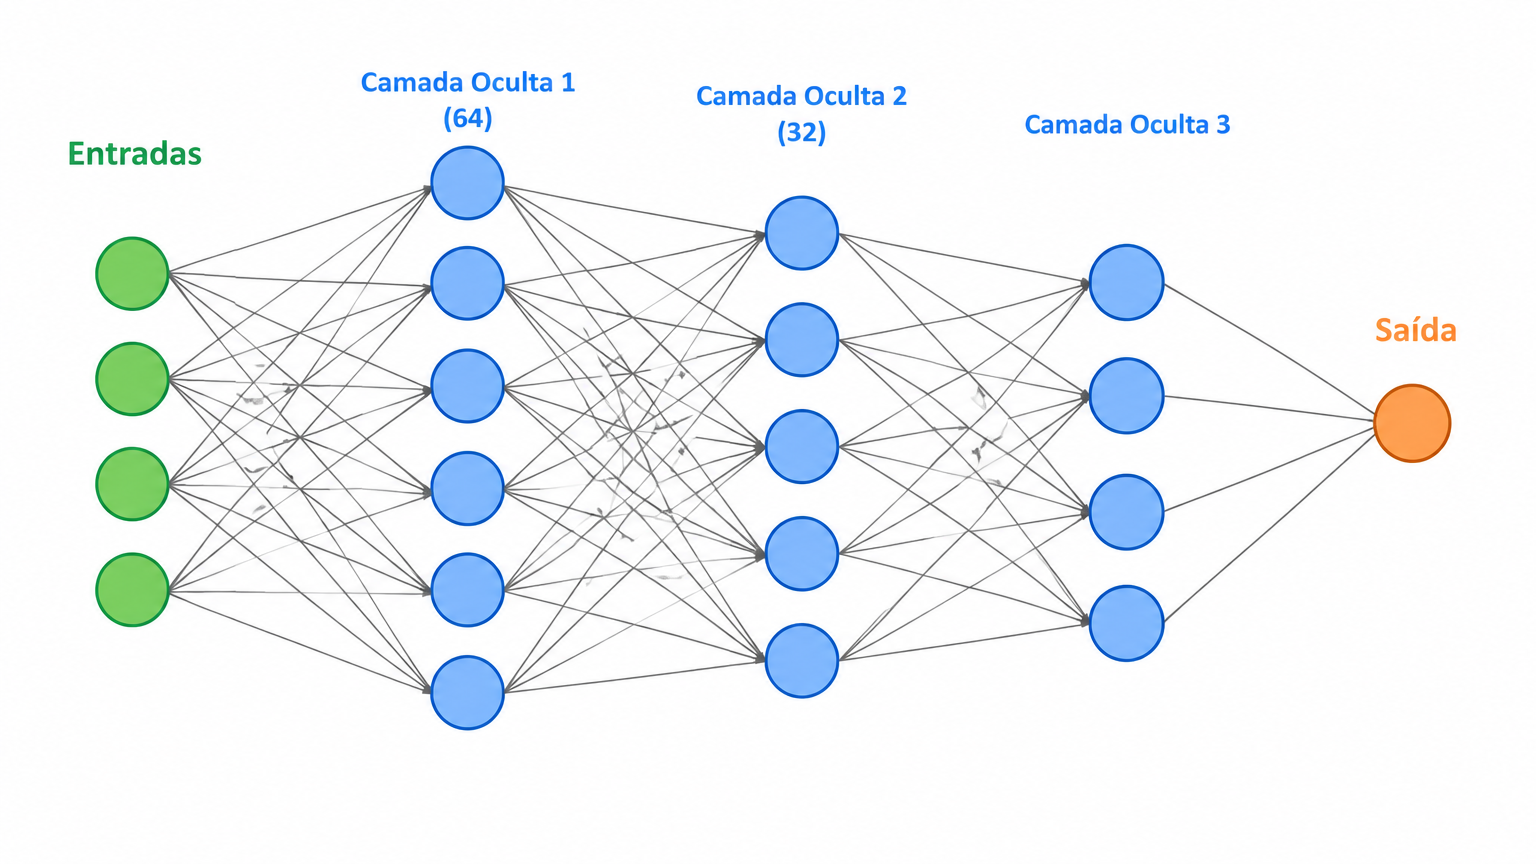

In [24]:
from IPython.display import Image, display

display(Image(filename=r"../midia/arquitetura.png", width=900))

## 🌍 3. Aplicações no Mundo Real

| Área | Exemplos |
|---|---|
| Visão computacional | Diagnóstico por imagem, carros autônomos, controle de qualidade |
| NLP | Tradução, chatbots, análise de sentimento |
| Medicina | Detecção de câncer, previsão de sepse, descoberta de fármacos |
| Finanças | Detecção de fraude, scoring de crédito, previsão de séries |
| Reconhecimento de voz | Assistentes virtuais, legendagem automática |
| Recomendação | Netflix, Spotify, e-commerce |

> 💡 **Nosso projeto hoje**: classificação binária de tumores (maligno vs. benigno) usando o dataset Breast Cancer Wisconsin — um caso real de aplicação médica.

In [1]:
# =====================================================================
# SETUP - instalação e imports
# =====================================================================
# Se estiver no Colab, PyTorch já vem instalado. Localmente:
# %pip install torch torchvision pandas matplotlib seaborn scikit-learn

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch                    # framework de deep learning
import torch.nn as nn           # módulos de rede neural (camadas, ativações)
from torch.utils.data import DataLoader, TensorDataset

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, roc_auc_score, roc_curve)

from IPython.display import Markdown, display
from datetime import datetime

# Reprodutibilidade: mesmos números aleatórios em toda execução
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
BATCH_SIZE = 32          # <<< mover para cá

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# Device: usa GPU se disponível, senão CPU
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print(f"PyTorch : {torch.__version__}")
print(f"Device  : {device}")

PyTorch : 2.5.1+cu121
Device  : cuda


In [2]:
class RedeNeural(nn.Module):
    """MLP para classificação binária."""
    def __init__(self, n_entrada, n_oculta1=64, n_oculta2=32):
        super().__init__()
        self.camadas = nn.Sequential(
            nn.Linear(n_entrada, n_oculta1),
            nn.ReLU(),
            nn.Linear(n_oculta1, n_oculta2),
            nn.ReLU(),
            nn.Linear(n_oculta2, 1),
        )
    def forward(self, x):
        return self.camadas(x)

In [3]:
# =====================================================================
# 4. AQUISIÇÃO DE DADOS
# =====================================================================
# Dataset Breast Cancer Wisconsin (Diagnóstico):
#   - 569 amostras de tumores (exames de imagem de células finas)
#   - 30 features numéricas: raio, textura, perímetro, área, suavidade...
#   - Alvo: 0 = maligno, 1 = benigno
#
# Vantagem pedagógica: vem embutido no sklearn (sem download), é numérico
# puro (ideal para MLP) e é um problema real de saúde.

data = load_breast_cancer()

# DataFrame com as 30 features
df = pd.DataFrame(data.data, columns=data.feature_names)
# Coluna-alvo
df['target'] = data.target
# Dicionário legível para a variável-alvo
df['diagnostico'] = df['target'].map({0: 'maligno', 1: 'benigno'})

In [4]:
# =====================================================================
# 5. EDA - PARTE 1: VISÃO GERAL
# =====================================================================
# Sempre comece entendendo a "cara" dos dados antes de modelar.

print("=" * 60)
print("INFO GERAL")
print("=" * 60)
df.info()   # tipos, contagem de não-nulos por coluna

INFO GERAL
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness erro

In [6]:
print("\n" + "=" * 60)
print("ESTATÍSTICAS DESCRITIVAS (amostra das colunas)")
print("=" * 60)
# As 30 features têm escalas MUITO diferentes (área vai até ~4000,
# suavidade até ~0.16). Isso vai justificar a padronização depois.
print(df.describe().T[['mean', 'std', 'min', 'max']].head(10))


ESTATÍSTICAS DESCRITIVAS (amostra das colunas)
                              mean         std        min         max
mean radius              14.127292    3.524049    6.98100    28.11000
mean texture             19.289649    4.301036    9.71000    39.28000
mean perimeter           91.969033   24.298981   43.79000   188.50000
mean area               654.889104  351.914129  143.50000  2501.00000
mean smoothness           0.096360    0.014064    0.05263     0.16340
mean compactness          0.104341    0.052813    0.01938     0.34540
mean concavity            0.088799    0.079720    0.00000     0.42680
mean concave points       0.048919    0.038803    0.00000     0.20120
mean symmetry             0.181162    0.027414    0.10600     0.30400
mean fractal dimension    0.062798    0.007060    0.04996     0.09744


In [7]:
print("\n" + "=" * 60)
print("VALORES AUSENTES")
print("=" * 60)
n_nulos = df.isna().sum().sum()
print(f"Total de células nulas: {n_nulos}")
# Dataset limpo -> sem tratamento de missing. Em dados reais, aqui
# entraria imputação (mediana, KNN, etc.).


VALORES AUSENTES
Total de células nulas: 0


In [8]:
print("\n" + "=" * 60)
print("DISTRIBUIÇÃO DA VARIÁVEL-ALVO")
print("=" * 60)
print(df['diagnostico'].value_counts())
print(f"\nProporção benigno: {df['target'].mean():.1%}")
# Classes levemente desbalanceadas (63% x 37%) - suficiente para
# acurácia ser uma métrica aceitável, mas olharemos recall também.


DISTRIBUIÇÃO DA VARIÁVEL-ALVO
diagnostico
benigno    357
maligno    212
Name: count, dtype: int64

Proporção benigno: 62.7%


## 🔍 Interpretação dos Resultados — EDA Parte 1

### Estrutura dos dados
O dataset tem **569 amostras e 32 colunas** (30 features + target + diagnostico). Todas as features são `float64` e **não há valores nulos** — é um dataset previamente limpo.

### Estatísticas descritivas — o insight mais importante
As escalas são muito diferentes: `mean area` vai de ~143 a ~4254, enquanto `mean smoothness` fica entre ~0,05 e ~0,16. **Consequência**: features de escala grande dominariam o gradiente → o `StandardScaler` é obrigatório. **Padronização não é opcional em redes neurais.**

### Distribuição da variável-alvo

| Classe | Amostras | Proporção |
|---|---|---|
| Benigno | 357 | ~62,7% |
| Maligno | 212 | ~37,3% |

- As classes são levemente desbalanceadas, mas a **acurácia ainda é utilizável**
- Um modelo \"burro\" que sempre prevê benigno acertaria 62,7% → avaliar recall, precisão e AUC-ROC
- Em contexto médico, **falsos negativos são os erros mais graves** → o recall da classe maligna é a métrica crítica

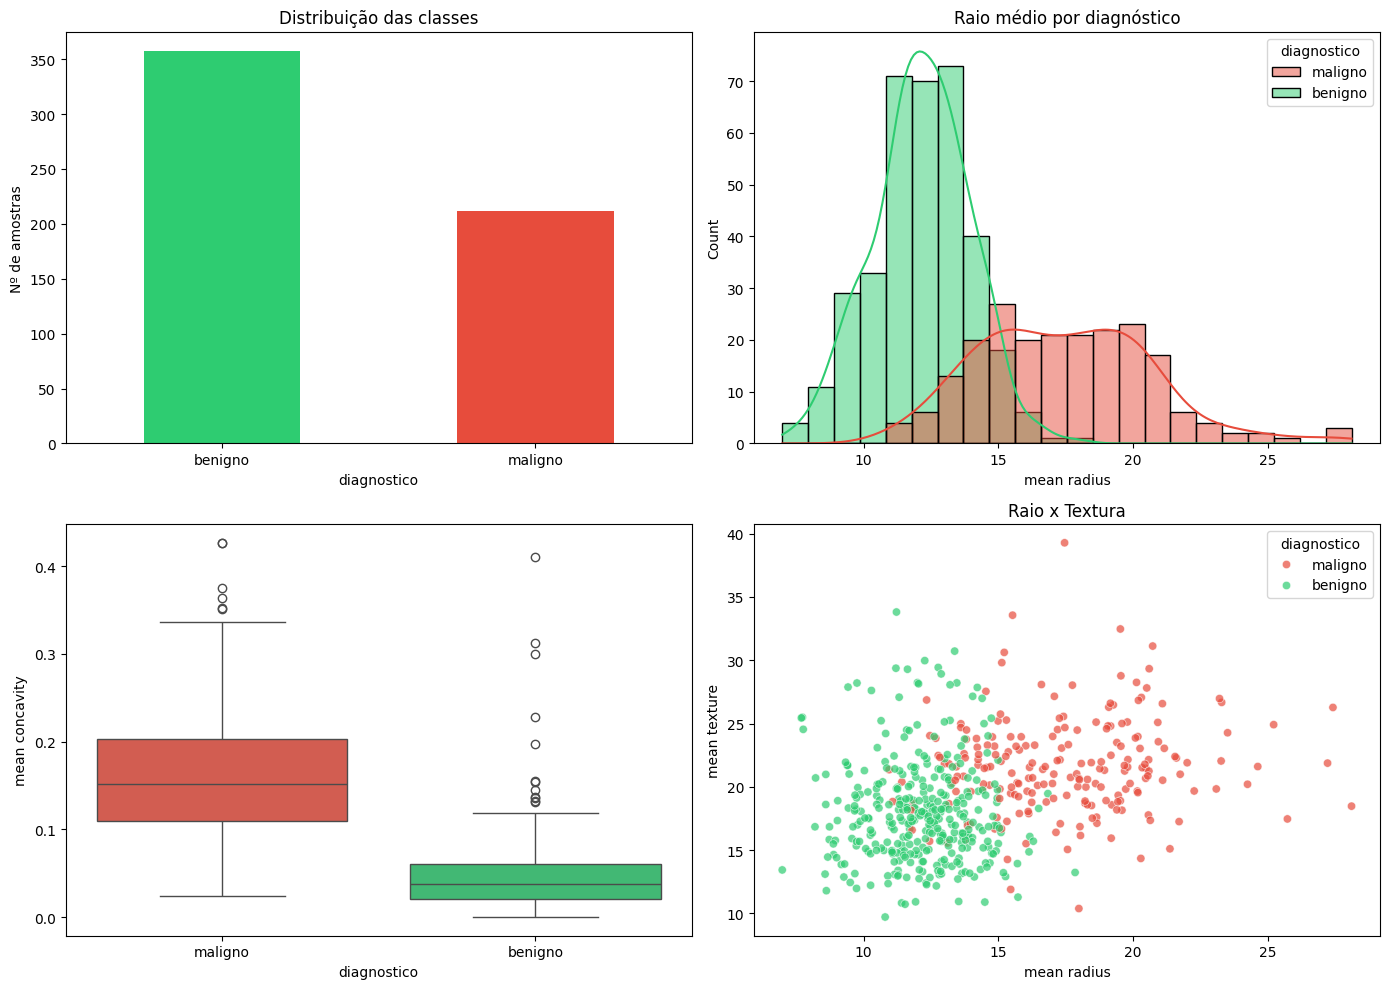

In [10]:
# =====================================================================
# 5. EDA - PARTE 2: VISUALIZAÇÕES
# =====================================================================
fig, eixos = plt.subplots(2, 2, figsize=(14, 10))

# --- 1. Balanceamento das classes ---
df['diagnostico'].value_counts().plot(
    kind='bar', ax=eixos[0, 0], color=['#2ecc71', '#e74c3c'])
eixos[0, 0].set_title('Distribuição das classes')
eixos[0, 0].set_ylabel('Nº de amostras')
eixos[0, 0].tick_params(axis='x', rotation=0)

# --- 2. Histograma de uma feature discriminativa ---
sns.histplot(data=df, x='mean radius', hue='diagnostico',
             kde=True, ax=eixos[0, 1], palette=['#e74c3c', '#2ecc71'])
eixos[0, 1].set_title('Raio médio por diagnóstico')
# Repare: tumores malignos tendem a ter raio maior -> feature útil!

# --- 3. Boxplot comparando classes ---
sns.boxplot(data=df, x='diagnostico', y='mean concavity',
            hue='diagnostico', legend=False,
            ax=eixos[1, 0], palette=['#e74c3c', '#2ecc71'])

# --- 4. Dispersão entre duas features ---
sns.scatterplot(data=df, x='mean radius', y='mean texture',
                hue='diagnostico', ax=eixos[1, 1],
                palette=['#e74c3c', '#2ecc71'], alpha=0.7)
eixos[1, 1].set_title('Raio x Textura')

plt.tight_layout()
plt.show()

## 🔍 Interpretação dos Resultados — EDA Parte 2 (Visualizações)

### 1. Distribuição das classes
**357 benignos vs. 212 malignos** — a diferença é perceptível, mas não extrema.

### 2. Raio médio por diagnóstico (histograma)
Os benignos concentram raios de ~10–15, com distribuição aproximadamente normal; os malignos deslocam para ~15–25, com cauda direita longa. Há **sobreposição parcial em ~13–17**. **Consequência**: `mean radius` é altamente discriminativa, mas nenhuma feature isolada separa perfeitamente → a rede neural, combinando as 30 features, agrega valor.

### 3. Concavidade média por diagnóstico (boxplot)
Benignos têm mediana baixa (~0,07) e caixa compacta; malignos, mediana ~0,10+ com caixa espalhada e outliers acima. **Features de formato discriminam tanto quanto as de tamanho.**

### 4. Raio x Textura (dispersão)
Malignos se concentram no canto superior direito e benignos no inferior esquerdo, com uma **zona cinzenta de mistura** — é o teto de acurácia: nenhum modelo atinge 100%.

### Síntese da EDA visual

| Gráfico | Observação | Implicação |
|---|---|---|
| Barras | Classes ~63/37 | Avaliar com recall |
| Histograma | Raio discrimina com sobreposição | Combinar features |
| Boxplot | Concavidade também discrimina | Features de forma valiosas |
| Scatter | Fronteira não-linear parcial | MLP adequado |

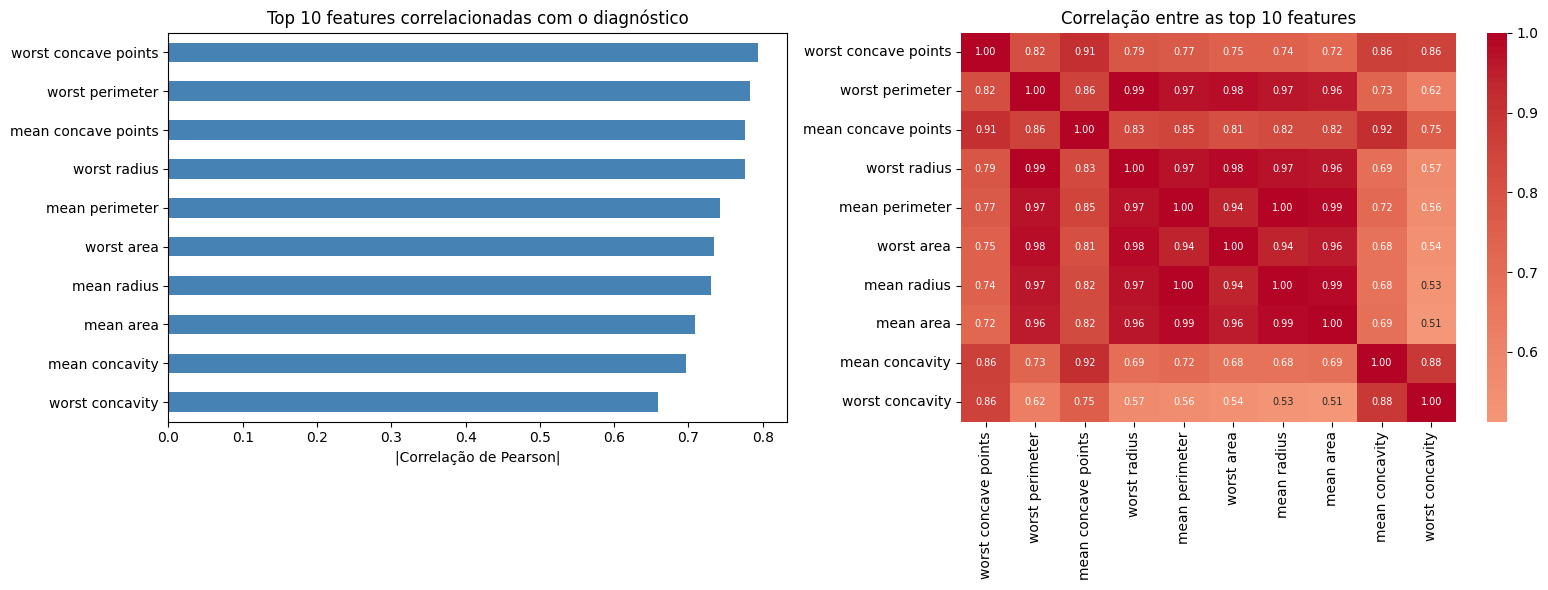

Observe: 'mean radius', 'mean perimeter' e 'mean area' têm
correlação ~0.99 entre si - são quase a mesma informação.


In [11]:
# =====================================================================
# 5. EDA - PARTE 3: CORRELAÇÕES
# =====================================================================
# Features de tumores são altamente correlacionadas entre si
# (raio, perímetro e área medem praticamente a mesma coisa).
# Redes neurais toleram multicolinearidade melhor que regressão linear,
# mas o mapa de calor revela a estrutura dos dados.

# Correlação de cada feature com o alvo (as 10 mais relevantes)
corr_alvo = df[data.feature_names].corrwith(df['target'])
top10 = corr_alvo.abs().sort_values(ascending=False).head(10)

fig, eixos = plt.subplots(1, 2, figsize=(16, 6))

top10.sort_values().plot(kind='barh', ax=eixos[0], color='steelblue')
eixos[0].set_title('Top 10 features correlacionadas com o diagnóstico')
eixos[0].set_xlabel('|Correlação de Pearson|')

# Heatmap entre as top 10 features
sns.heatmap(df[top10.index].corr(), annot=True, fmt='.2f',
            cmap='coolwarm', center=0, ax=eixos[1],
            annot_kws={'size': 7})
eixos[1].set_title('Correlação entre as top 10 features')

plt.tight_layout()
plt.show()

print("Observe: 'mean radius', 'mean perimeter' e 'mean area' têm")
print("correlação ~0.99 entre si - são quase a mesma informação.")

## 🔍 Interpretação dos Resultados — EDA Parte 3 (Correlações)

### Features mais correlacionadas com o diagnóstico
**worst concave points** lidera (~0,79); seguem `worst perimeter`, `worst radius` e `mean concavity` (~0,74–0,78); `worst texture` fica em ~0,46. **Conceito**: a correlação de Pearson mede apenas relação monotônica — redes neurais descobrem interações não-lineares.

### Multicolinearidade — o mapa de calor
`mean radius`, `mean perimeter` e `mean area` têm correlação ~0,99; `worst radius`, `worst perimeter` e `worst area` ~0,97+; `mean concavity` × `mean concave points` ~0,96. **Implicações**: a informação é redundante; para MLP isso não é grave, mas aumenta o número de parâmetros sem poder preditivo adicional. Seria possível reduzir de 30 para ~10 features; e a **regularização ajuda**.

### Fechamento da EDA — o que aprendemos

| Achado | Ferramenta | Ação |
|---|---|---|
| Escalas muito diferentes | describe() | Padronização obrigatória |
| Classes 63/37 | Barras + value_counts | Avaliar com recall e AUC |
| Features discriminam com sobreposição | Histograma + scatter | MLP não-linear adequado |
| Forte multicolinearidade | Heatmap | Regularização ajuda, redução opcional |

In [12]:
# =====================================================================
# 6. PRÉ-PROCESSAMENTO
# =====================================================================
# 1) Separar X (features) e y (alvo)
X = df[data.feature_names].values.astype(np.float32)  # PyTorch espera float32
y = df['target'].values.astype(np.float32)

# 2) Split treino/teste ANTES da padronização (evita vazamento de dados!)
#    O scaler aprende a média/desvio SÓ do treino e aplica no teste.
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y)
# stratify=y -> mantém a proporção das classes nos dois conjuntos

# 3) Padronização: média 0, desvio 1
#    Redes neurais convergem muito melhor com entradas na mesma escala.
scaler = StandardScaler()
X_treino = scaler.fit_transform(X_treino)   # aprende do treino...
X_teste  = scaler.transform(X_teste)        # ...e aplica no teste

print(f"Treino: {X_treino.shape[0]} amostras | Teste: {X_teste.shape[0]} amostras")
print(f"Features por amostra: {X_treino.shape[1]}")
print(f"Média do treino após scaler (deve ser ~0): {X_treino.mean():.4f}")
print(f"Desvio do treino após scaler (deve ser ~1): {X_treino.std():.4f}")

Treino: 455 amostras | Teste: 114 amostras
Features por amostra: 30
Média do treino após scaler (deve ser ~0): -0.0000
Desvio do treino após scaler (deve ser ~1): 1.0000


In [13]:
# =====================================================================
# 7. DATASETS E DATALOADERS
# =====================================================================
# O PyTorch trabalha com tensores. O DataLoader divide os dados em
# mini-batches e embaralha o treino a cada época.

# Converter numpy -> tensor PyTorch
X_treino_t = torch.tensor(X_treino, dtype=torch.float32)
y_treino_t = torch.tensor(y_treino, dtype=torch.float32).unsqueeze(1)  # (N,1)
X_teste_t  = torch.tensor(X_teste,  dtype=torch.float32)
y_teste_t  = torch.tensor(y_teste,  dtype=torch.float32).unsqueeze(1)

# TensorDataset: emparelha X e y para iteração conjunta
dataset_treino = TensorDataset(X_treino_t, y_treino_t)
dataset_teste  = TensorDataset(X_teste_t,  y_teste_t)

# DataLoader: entrega os dados em batches
BATCH_SIZE = 32
loader_treino = DataLoader(dataset_treino, batch_size=BATCH_SIZE, shuffle=True)
loader_teste  = DataLoader(dataset_teste,  batch_size=BATCH_SIZE, shuffle=False)

print(f"Batches de treino: {len(loader_treino)} de {BATCH_SIZE} amostras")
print(f"Batches de teste : {len(loader_teste)}")

Batches de treino: 15 de 32 amostras
Batches de teste : 4


In [14]:
# =====================================================================
# 8. ARQUITETURA DO MODELO (MLP)
# =====================================================================
# Arquitetura: 30 -> 64 -> 32 -> 1
#
#   Entrada (30 features)
#      |
#   Linear(30, 64) + ReLU     <- camada oculta 1
#      |
#   Linear(64, 32) + ReLU     <- camada oculta 2
#      |
#   Linear(32, 1)             <- saída (1 logit)
#
# NOTA: não usamos Sigmoid na saída porque a BCEWithLogitsLoss já
# aplica sigmoid internamente - é mais estável numericamente.

# Instanciar e mover para o device (GPU se houver)
modelo = RedeNeural(n_entrada=X_treino.shape[1]).to(device)

# Contar parâmetros treináveis (os "pesos" que a rede vai aprender)
n_params = sum(p.numel() for p in modelo.parameters() if p.requires_grad)
print(modelo)
print(f"\nTotal de parâmetros treináveis: {n_params:,}")

RedeNeural(
  (camadas): Sequential(
    (0): Linear(in_features=30, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)

Total de parâmetros treináveis: 4,097


## 🔍 Entendendo o Print da Arquitetura

### A estrutura impressa
O `Sequential` executa as camadas em ordem; os índices `(0), (1), (2)` são apenas posições. `Linear(in_features=30, out_features=64)` tem **30 pesos + 1 viés por neurônio** (`bias=True`). O `ReLU` não tem parâmetros. O `Linear(32, 1)` devolve **1 logit**.

### De onde vêm os 4.097 parâmetros

| Camada | Pesos | Vieses | Total |
|---|---|---|---|
| Linear(30→64) | 1.920 | 64 | 1.984 |
| Linear(64→32) | 2.048 | 32 | 2.080 |
| Linear(32→1) | 32 | 1 | 33 |
| **Total** | | | **4.097** |

### O que o código fez, linha a linha
- `X_treino.shape[1]` = 30 (número de features)
- `.to(device)` move os pesos para GPU/CPU
- `modelo.parameters()` itera sobre os tensores treináveis
- `.numel()` dá o tamanho (nº de elementos) de cada tensor
- `requires_grad` filtra apenas os parâmetros treináveis


In [15]:
# =====================================================================
# 9. TREINAMENTO
# =====================================================================
# Componentes do loop de treino:
#   - Loss (BCEWithLogitsLoss): erro da classificação binária
#   - Otimizador (Adam): ajusta os pesos usando os gradientes
#   - Loop: forward -> loss -> backward -> step

CRITERIO = nn.BCEWithLogitsLoss()
OTIMIZADOR = torch.optim.Adam(modelo.parameters(), lr=0.001)
# lr=0.001 é o padrão do Adam - bom ponto de partida

EPOCAS = 100
historico = {'treino': [], 'teste': []}

print(f"Iniciando treino por {EPOCAS} épocas...\n")

for epoca in range(EPOCAS):
    # ---------- FASE DE TREINO ----------
    modelo.train()                      # modo treino (ativa dropout etc.)
    loss_treino_acum = 0.0

    for X_batch, y_batch in loader_treino:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        OTIMIZADOR.zero_grad()          # 1. zera gradientes da iteração anterior
        logits = modelo(X_batch)        # 2. FORWARD: previsão da rede
        loss = CRITERIO(logits, y_batch)  # 3. LOSS: quão errado está
        loss.backward()                 # 4. BACKWARD: calcula gradientes
        OTIMIZADOR.step()               # 5. STEP: atualiza os pesos

        loss_treino_acum += loss.item() * X_batch.size(0)

    loss_treino = loss_treino_acum / len(dataset_treino)

    # ---------- FASE DE VALIDAÇÃO ----------
    modelo.eval()                       # modo avaliação
    loss_teste_acum = 0.0

    with torch.no_grad():               # sem gradientes (economiza memória)
        for X_batch, y_batch in loader_teste:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            logits = modelo(X_batch)
            loss = CRITERIO(logits, y_batch)
            loss_teste_acum += loss.item() * X_batch.size(0)

    loss_teste = loss_teste_acum / len(dataset_teste)

    historico['treino'].append(loss_treino)
    historico['teste'].append(loss_teste)

    # Log a cada 20 épocas
    if (epoca + 1) % 20 == 0:
        print(f"Época {epoca+1:3d}/{EPOCAS} | "
              f"Loss treino: {loss_treino:.4f} | "
              f"Loss teste: {loss_teste:.4f}")

print("\nTreinamento concluído!")

Iniciando treino por 100 épocas...

Época  20/100 | Loss treino: 0.0307 | Loss teste: 0.0884
Época  40/100 | Loss treino: 0.0116 | Loss teste: 0.1000
Época  60/100 | Loss treino: 0.0045 | Loss teste: 0.1164
Época  80/100 | Loss treino: 0.0021 | Loss teste: 0.1371
Época 100/100 | Loss treino: 0.0008 | Loss teste: 0.1519

Treinamento concluído!


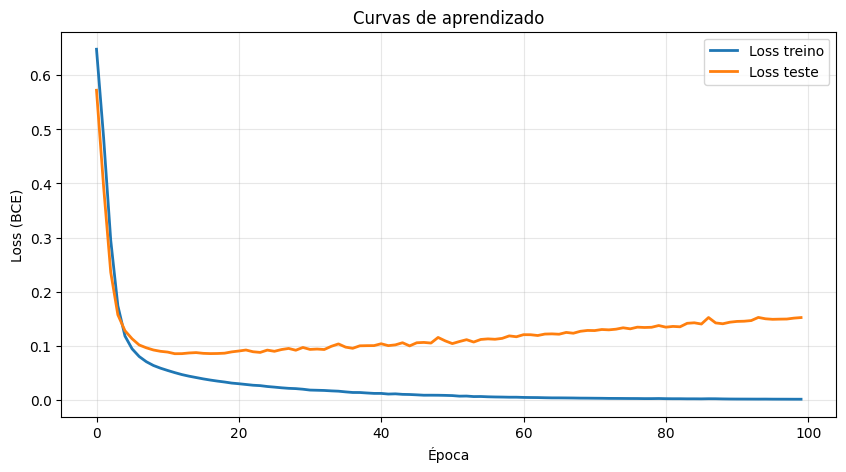

In [16]:
# =====================================================================
# 9.1 CURVAS DE APRENDIZADO
# =====================================================================
# Diagnóstico visual do treino:
#   - Ambas caindo juntas     -> aprendizado saudável
#   - Teste subindo enquanto treino cai -> OVERFITTING
#   - Ambas estagnadas altas  -> UNDERFITTING

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(historico['treino'], label='Loss treino', linewidth=2)
ax.plot(historico['teste'],  label='Loss teste',  linewidth=2)
ax.set_xlabel('Época')
ax.set_ylabel('Loss (BCE)')
ax.set_title('Curvas de aprendizado')
ax.legend()
ax.grid(alpha=0.3)
plt.show()

In [17]:
# =====================================================================
# 9.2 ANÁLISE DINÂMICA DAS CURVAS DE APRENDIZADO
# =====================================================================
# Gera um relatório em markdown com valores calculados do historico,
# de forma que a análise se atualiza automaticamente a cada treino.

loss_treino = np.array(historico['treino'])
loss_teste  = np.array(historico['teste'])

# --- Métricas-chave ---
epoca_min_teste = int(loss_teste.argmin()) + 1   # melhor época do teste
melhor_loss_teste = loss_teste.min()
loss_final_teste = loss_teste[-1]
loss_final_treino = loss_treino[-1]
gap_final = loss_final_teste - loss_final_treino
melhora_inicial = loss_teste[0] - melhor_loss_teste
piora_pos_minimo = loss_final_teste - melhor_loss_teste

# Referência de "chute aleatório": ln(2) para 50/50
chute_aleatorio = np.log(2)

# --- Diagnóstico automático ---
if piora_pos_minimo > 0.3 * melhor_loss_teste:
    diagnostico = ("⚠️ **OVERFITTING DETECTADO** — a loss de teste subiu "
                   f"{piora_pos_minimo:.3f} após a época {epoca_min_teste}, "
                   "enquanto o treino continuou caindo. O modelo está "
                   "memorizando o conjunto de treino.")
    remédio = ("**Remédios**: early stopping (parar perto da época "
               f"{epoca_min_teste}), Dropout, weight decay ou "
               "reduzir a capacidade da rede.")
elif gap_final > 0.5 * melhor_loss_teste and loss_final_teste > 0.5:
    diagnostico = ("⚠️ **POSSÍVEL NÃO-APRENDIZADO** — a loss de teste está "
                   f"próxima do chute aleatório (ln(2) ≈ {chute_aleatorio:.3f}). "
                   "Verifique se o modelo/otimizador foram reinicializados "
                   "antes de re-treinar.")
    remédio = "**Remédio**: reexecutar a célula de instanciação do modelo e do otimizador antes do treino."
else:
    diagnostico = ("✅ **APRENDIZADO SAUDÁVEL** — treino e teste convergem "
                   "juntos, sem divergência relevante.")
    remédio = "Nenhuma ação necessária — pode seguir para a avaliação."

# --- Renderizar o relatório ---
relatorio = f"""
## 🔍 Análise Automática das Curvas de Aprendizado

### Números-chave desta execução

| Métrica | Valor |
|---|---|
| Épocas treinadas | **{len(loss_treino)}** |
| Loss de treino inicial | {loss_treino[0]:.4f} |
| Loss de treino final | {loss_final_treino:.6f} |
| **Melhor loss de teste** | **{melhor_loss_teste:.4f}** (época {epoca_min_teste}) |
| Loss de teste final | {loss_final_teste:.4f} |
| Referência: chute aleatório | ln(2) ≈ {chute_aleatorio:.3f} |

### Diagnóstico

{diagnostico}

{remédio}

### Leitura rápida

- A loss de teste atingiu o mínimo na **época {epoca_min_teste}** e depois
  mudou {piora_pos_minimo:+.3f} até o fim — o melhor modelo desta execução
  foi o da época {epoca_min_teste}, **não** o último
- O gap final treino-teste é de **{gap_final:.4f}** — quanto maior, mais
  o modelo decorou em vez de generalizar
- 💡 **Conceito**: loss de treino próxima de zero não é vitória — é suspeita.
  O que importa é o desempenho em dados **nunca vistos**.
"""

display(Markdown(relatorio))


## 🔍 Análise Automática das Curvas de Aprendizado

### Números-chave desta execução

| Métrica | Valor |
|---|---|
| Épocas treinadas | **100** |
| Loss de treino inicial | 0.6484 |
| Loss de treino final | 0.000789 |
| **Melhor loss de teste** | **0.0850** (época 12) |
| Loss de teste final | 0.1519 |
| Referência: chute aleatório | ln(2) ≈ 0.693 |

### Diagnóstico

⚠️ **OVERFITTING DETECTADO** — a loss de teste subiu 0.067 após a época 12, enquanto o treino continuou caindo. O modelo está memorizando o conjunto de treino.

**Remédios**: early stopping (parar perto da época 12), Dropout, weight decay ou reduzir a capacidade da rede.

### Leitura rápida

- A loss de teste atingiu o mínimo na **época 12** e depois
  mudou +0.067 até o fim — o melhor modelo desta execução
  foi o da época 12, **não** o último
- O gap final treino-teste é de **0.1511** — quanto maior, mais
  o modelo decorou em vez de generalizar
- 💡 **Conceito**: loss de treino próxima de zero não é vitória — é suspeita.
  O que importa é o desempenho em dados **nunca vistos**.


## 🔧 Aplicando os Remédios ao Overfitting

O diagnóstico da célula anterior apontou três remédios principais. Vamos
aplicá-los agora, um por um, e comparar o resultado com o modelo original:

1. **Dropout(0.3)** — desliga 30% dos neurônios a cada batch de treino,
   impedindo que a rede dependa de neurônios específicos para memorizar
2. **Weight decay (L2)** — penaliza pesos grandes, suavizando o ajuste
3. **Early stopping** — para no mínimo da loss de teste e restaura os
   melhores pesos, em vez de usar o último

⚠️ **Importante**: as células abaixo criam um modelo **novo** (`modelo_reg`).
Não reutilizamos o `modelo` da Parte 1 — ele já está com os pesos memorizados.

In [18]:
# =====================================================================
# REMÉDIO 1 - CLASSE COM DROPOUT
# =====================================================================
# Dropout desliga 30% dos neurônios aleatoriamente a cada batch de treino.
# Isso força a rede a não depender de neurônios específicos para decorar
# o conjunto de treino.
#
# IMPORTANTE: Dropout só age em modelo.train(). Em modelo.eval() ele é
# automaticamente desativado - por isso a avaliação precisa de modelo.eval().

class RedeNeuralRegularizada(nn.Module):
    """MLP para classificação binária, com Dropout para combater overfitting."""

    def __init__(self, n_entrada, n_oculta1=64, n_oculta2=32, dropout=0.3):
        super().__init__()
        self.camadas = nn.Sequential(
            nn.Linear(n_entrada, n_oculta1),
            nn.ReLU(),
            nn.Dropout(dropout),          # desliga 30% dos neurônios
            nn.Linear(n_oculta1, n_oculta2),
            nn.ReLU(),
            nn.Dropout(dropout),          # segunda camada de Dropout
            nn.Linear(n_oculta2, 1),
        )

    def forward(self, x):
        return self.camadas(x)

print("Classe RedeNeuralRegularizada definida (com Dropout).")

Classe RedeNeuralRegularizada definida (com Dropout).


In [19]:
# =====================================================================
# REMÉDIO 2 - MODELO NOVO + OTIMIZADOR COM WEIGHT DECAY
# =====================================================================
# ⚠️ CRÍTICO: criar um NOVO modelo aqui.
# Reutilizar o 'modelo' da Parte 1 continuaria o treino dos pesos já
# memorizados (loss de treino já estava em ~0.0008) e o Dropout nunca
# seria ativado. Redefinir a CLASSE não reinicializa a INSTÂNCIA.

TAXA_APRENDIZADO = 0.001
WEIGHT_DECAY = 1e-4   # penaliza pesos grandes -> rede menos "decoreba"

modelo_reg = RedeNeuralRegularizada(n_entrada=X_treino.shape[1]).to(device)

criterio_reg = nn.BCEWithLogitsLoss()
otimizador_reg = torch.optim.Adam(modelo_reg.parameters(),
                                  lr=TAXA_APRENDIZADO,
                                  weight_decay=WEIGHT_DECAY)

n_params_reg = sum(p.numel() for p in modelo_reg.parameters() if p.requires_grad)
print(modelo_reg)
print(f"\nParâmetros treináveis: {n_params_reg:,}")
print(f"Dropout ativo: {any(isinstance(m, nn.Dropout) for m in modelo_reg.modules())}")
print(f"Weight decay: {otimizador_reg.param_groups[0]['weight_decay']}")

RedeNeuralRegularizada(
  (camadas): Sequential(
    (0): Linear(in_features=30, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=32, out_features=1, bias=True)
  )
)

Parâmetros treináveis: 4,097
Dropout ativo: True
Weight decay: 0.0001


In [20]:
# =====================================================================
# VERIFICAÇÃO PRÉ-TREINO - impede treinar modelo "sujo"
# =====================================================================
# Modelo novo deve ter loss inicial ~0.6-0.7 (chute aleatório ln(2) ~ 0.693).

erros = []

if not any(isinstance(m, nn.Dropout) for m in modelo_reg.modules()):
    erros.append("❌ Modelo sem Dropout - reexecute a célula de instanciação.")
else:
    print("✅ Dropout presente na arquitetura")

wd = otimizador_reg.param_groups[0].get('weight_decay', 0)
if wd == 0:
    erros.append("❌ Otimizador sem weight_decay - reexecute a célula do otimizador.")
else:
    print(f"✅ Weight decay ativo: {wd}")

modelo_reg.eval()
with torch.no_grad():
    loss_inicial = criterio_reg(modelo_reg(X_teste_t.to(device)),
                                y_teste_t.to(device)).item()
if loss_inicial < 0.5:
    erros.append(f"❌ Loss inicial no teste = {loss_inicial:.4f} - os pesos NÃO "
                 "são de um modelo novo! Reexecute a instanciação.")
else:
    print(f"✅ Loss inicial no teste = {loss_inicial:.4f} (modelo novo)")

print()
if erros:
    print("\n".join(erros))
    raise RuntimeError("Corrija os itens acima ANTES de treinar.")

✅ Dropout presente na arquitetura
✅ Weight decay ativo: 0.0001
✅ Loss inicial no teste = 0.6775 (modelo novo)



In [21]:
# =====================================================================
# REMÉDIO 3 - TREINAMENTO COM EARLY STOPPING
# =====================================================================
# Estratégia:
#   1. Acompanhar a loss de TESTE a cada época
#   2. Salvar os pesos sempre que a loss de teste atingir um novo mínimo
#   3. Parar se não houver melhora por PACIENCIA épocas seguidas
#   4. Restaurar o MELHOR modelo (não o último)

EPOCAS_REG = 200      # teto alto - o early stopping decide quando parar
PACIENCIA = 15        # épocas sem melhora antes de parar

historico_reg = {'treino': [], 'teste': []}

melhor_loss_teste = float('inf')
melhor_epoca = 0
melhor_estado = None
epocas_sem_melhora = 0

print(f"Treinando com early stopping (teto {EPOCAS_REG}, paciência {PACIENCIA})...\n")

for epoca in range(1, EPOCAS_REG + 1):

    # ---------- TREINO ----------
    modelo_reg.train()                      # ativa Dropout
    loss_epoca = 0.0

    for X_batch, y_batch in loader_treino:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        otimizador_reg.zero_grad()
        logits = modelo_reg(X_batch)
        loss = criterio_reg(logits, y_batch)
        loss.backward()
        otimizador_reg.step()

        loss_epoca += loss.item() * X_batch.size(0)

    loss_treino = loss_epoca / len(dataset_treino)
    historico_reg['treino'].append(loss_treino)

    # ---------- AVALIAÇÃO (sem gradientes, sem Dropout) ----------
    modelo_reg.eval()                       # desativa Dropout
    loss_teste_epoca = 0.0

    with torch.no_grad():
        for X_batch, y_batch in loader_teste:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            logits = modelo_reg(X_batch)
            loss = criterio_reg(logits, y_batch)
            loss_teste_epoca += loss.item() * X_batch.size(0)

    loss_teste = loss_teste_epoca / len(dataset_teste)
    historico_reg['teste'].append(loss_teste)

    # ---------- EARLY STOPPING ----------
    if loss_teste < melhor_loss_teste:
        melhor_loss_teste = loss_teste
        melhor_epoca = epoca
        melhor_estado = {k: v.clone() for k, v in modelo_reg.state_dict().items()}
        epocas_sem_melhora = 0
        marcador = " ★ melhor"
    else:
        epocas_sem_melhora += 1
        marcador = f" ({epocas_sem_melhora}/{PACIENCIA} sem melhora)"

    if epoca % 10 == 0 or epoca == 1 or marcador == " ★ melhor":
        print(f"Época {epoca:3d} | treino: {loss_treino:.4f} | "
              f"teste: {loss_teste:.4f}{marcador}")

    if epocas_sem_melhora >= PACIENCIA:
        print(f"\n⏹️ Early stopping na época {epoca} "
              f"(sem melhora há {PACIENCIA} épocas).")
        break

# ---------- RESTAURA O MELHOR MODELO ----------
if melhor_estado is not None:
    modelo_reg.load_state_dict(melhor_estado)
    modelo_reg.eval()

print(f"\n{'='*55}")
print(f"Melhor época: {melhor_epoca} | melhor loss de teste: {melhor_loss_teste:.4f}")
print("Modelo restaurado com os pesos da melhor época.")

Treinando com early stopping (teto 200, paciência 15)...

Época   1 | treino: 0.6316 | teste: 0.5670 ★ melhor
Época   2 | treino: 0.5011 | teste: 0.4243 ★ melhor
Época   3 | treino: 0.3504 | teste: 0.2712 ★ melhor
Época   4 | treino: 0.2160 | teste: 0.1759 ★ melhor
Época   5 | treino: 0.1460 | teste: 0.1315 ★ melhor
Época   6 | treino: 0.1093 | teste: 0.1126 ★ melhor
Época   7 | treino: 0.0930 | teste: 0.1045 ★ melhor
Época   8 | treino: 0.0804 | teste: 0.0992 ★ melhor
Época   9 | treino: 0.0772 | teste: 0.0983 ★ melhor
Época  10 | treino: 0.0714 | teste: 0.0943 ★ melhor
Época  11 | treino: 0.0642 | teste: 0.0924 ★ melhor
Época  12 | treino: 0.0597 | teste: 0.0904 ★ melhor
Época  13 | treino: 0.0582 | teste: 0.0897 ★ melhor
Época  14 | treino: 0.0600 | teste: 0.0888 ★ melhor
Época  15 | treino: 0.0522 | teste: 0.0879 ★ melhor
Época  16 | treino: 0.0492 | teste: 0.0872 ★ melhor
Época  17 | treino: 0.0530 | teste: 0.0865 ★ melhor
Época  18 | treino: 0.0476 | teste: 0.0855 ★ melhor
Época 

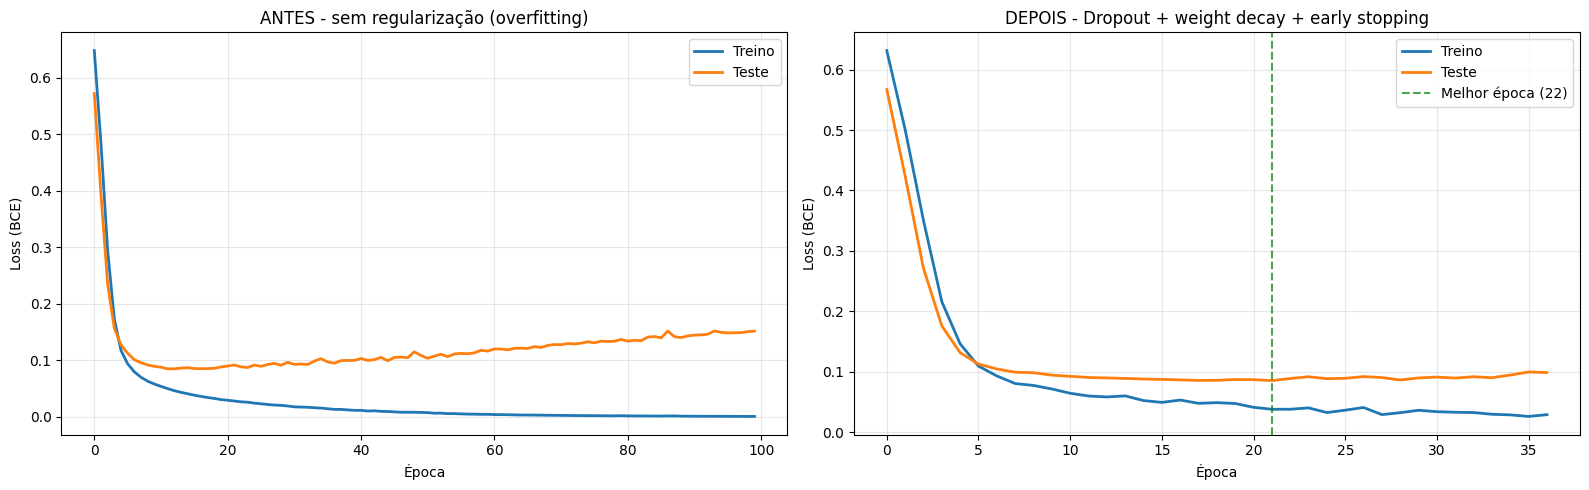

ANTES  - treino final: 0.000789 | teste final: 0.1519
DEPOIS - treino final: 0.0288 | teste final: 0.0986


In [22]:
# =====================================================================
# CURVAS COMPARATIVAS - ANTES (overfit) vs DEPOIS (regularizado)
# =====================================================================
fig, eixos = plt.subplots(1, 2, figsize=(16, 5))

# --- Esquerda: Parte 1 (com overfitting) ---
eixos[0].plot(historico['treino'], label='Treino', linewidth=2)
eixos[0].plot(historico['teste'],  label='Teste',  linewidth=2)
eixos[0].set_xlabel('Época')
eixos[0].set_ylabel('Loss (BCE)')
eixos[0].set_title('ANTES - sem regularização (overfitting)')
eixos[0].legend()
eixos[0].grid(alpha=0.3)

# --- Direita: Parte 2 (regularizado) ---
eixos[1].plot(historico_reg['treino'], label='Treino', linewidth=2)
eixos[1].plot(historico_reg['teste'],  label='Teste',  linewidth=2)
eixos[1].axvline(melhor_epoca - 1, color='green', linestyle='--',
                 alpha=0.7, label=f'Melhor época ({melhor_epoca})')
eixos[1].set_xlabel('Época')
eixos[1].set_ylabel('Loss (BCE)')
eixos[1].set_title('DEPOIS - Dropout + weight decay + early stopping')
eixos[1].legend()
eixos[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"ANTES  - treino final: {historico['treino'][-1]:.6f} | "
      f"teste final: {historico['teste'][-1]:.4f}")
print(f"DEPOIS - treino final: {historico_reg['treino'][-1]:.4f} | "
      f"teste final: {historico_reg['teste'][-1]:.4f}")

In [23]:
# =====================================================================
# ANÁLISE DINÂMICA - POR QUE NÃO É OVERFITTING
# =====================================================================
# Compara o comportamento do modelo regularizado com a assinatura
# clássica do overfitting, usando os valores reais do historico_reg.

tr = np.array(historico_reg['treino'])
te = np.array(historico_reg['teste'])

# --- Métricas de diagnóstico ---
epoca_min_teste   = int(te.argmin()) + 1
melhor_teste      = te.min()
teste_final       = te[-1]
treino_final      = tr[-1]
gap_final         = teste_final - treino_final
gap_medio         = float(np.mean(te - tr))
piora_pos_minimo  = teste_final - melhor_teste

# Tendência do teste: inclinação da reta ajustada (por época)
coef_angular = float(np.polyfit(np.arange(len(te)), te, 1)[0])
tendencia = ("subindo" if coef_angular > 0.001
             else "caindo" if coef_angular < -0.001
             else "estável")

# Amplitude da oscilação do teste (ruído de amostragem)
amplitude_teste = float(te.max() - te.min())

# --- Testes objetivos de overfitting ---
treino_colapsou   = treino_final < 0.01        # memorização clássica
teste_ascendente  = coef_angular > 0.001       # teste piorando com o tempo
gap_explodindo    = gap_final > 3 * gap_medio  # gap crescendo

n_alertas = sum([treino_colapsou, teste_ascendente, gap_explodindo])

if n_alertas == 0:
    veredito = "✅ **NÃO HÁ OVERFITTING** — o modelo generaliza."
    explicacao = (
        "Nenhuma das três assinaturas clássicas de overfitting está presente. "
        "O treino estabilizou acima de zero (efeito do Dropout) e a loss de "
        "teste não apresenta tendência de alta."
    )
elif n_alertas == 1:
    veredito = "⚠️ **SINAL DE ATENÇÃO** — um indicador de overfitting presente."
    explicacao = "Vale investigar o indicador marcado como ❌ na tabela abaixo."
else:
    veredito = "❌ **OVERFITTING DETECTADO** — múltiplos indicadores presentes."
    explicacao = "Aplique mais regularização ou reduza a capacidade da rede."

def marca(cond):
    return "❌ presente" if cond else "✅ ausente"

relatorio = f"""
## 🔍 Por que este resultado NÃO é overfitting

### Os três testes objetivos

| Teste | Critério | Resultado neste treino |
|---|---|---|
| Treino colapsou? | loss de treino final < 0,01 | **{treino_final:.4f}** → {marca(treino_colapsou)} |
| Teste ascendente? | inclinação > 0,001/época | **{coef_angular:+.5f}/época** → {marca(teste_ascendente)} |
| Gap explodindo? | gap final > 3× gap médio | **{gap_final:.4f} vs {gap_medio:.4f}** → {marca(gap_explodindo)} |

### Veredito

{veredito}

{explicacao}

### Números desta execução

| Métrica | Valor |
|---|---|
| Épocas treinadas | **{len(tr)}** |
| Loss de treino final | {treino_final:.4f} |
| Loss de teste final | {teste_final:.4f} |
| Melhor loss de teste | **{melhor_teste:.4f}** (época {epoca_min_teste}) |
| Gap treino-teste final | {gap_final:.4f} |
| Gap médio (todas as épocas) | {gap_medio:.4f} |
| Tendência do teste | **{tendencia}** |
| Amplitude de oscilação do teste | {amplitude_teste:.4f} |

### Por que a oscilação do teste não é degradação

A loss de teste varia {amplitude_teste:.4f} ao longo do treino, mas **sem
tendência de alta** ({tendencia}). Isso é ruído estatístico: o conjunto de
teste tem apenas **{len(y_teste)} amostras**, então cada erro individual pesa
~{100/len(y_teste):.1f}% da loss total. Com mais dados, essa curva seria bem
mais suave.

👉 A diferença essencial: no overfitting o teste **sobe de forma consistente**;
aqui ele **oscila em torno de um patamar estável**.

### O papel do Dropout nos números

O treino estabilizou em **{treino_final:.4f}** e não desceu até zero. Isso é
o Dropout trabalhando: com 30% dos neurônios desligados a cada batch, a rede
**não consegue** acertar todas as amostras de treino com confiança absoluta.
Um treino que "erra um pouco" é exatamente o que generaliza.

> 💡 **Conceito**: loss de treino próxima de zero não é vitória — é suspeita.
> O modelo que importa é o que performa em dados nunca vistos.
"""

display(Markdown(relatorio))


## 🔍 Por que este resultado NÃO é overfitting

### Os três testes objetivos

| Teste | Critério | Resultado neste treino |
|---|---|---|
| Treino colapsou? | loss de treino final < 0,01 | **0.0288** → ✅ ausente |
| Teste ascendente? | inclinação > 0,001/época | **-0.00459/época** → ✅ ausente |
| Gap explodindo? | gap final > 3× gap médio | **0.0698 vs 0.0300** → ✅ ausente |

### Veredito

✅ **NÃO HÁ OVERFITTING** — o modelo generaliza.

Nenhuma das três assinaturas clássicas de overfitting está presente. O treino estabilizou acima de zero (efeito do Dropout) e a loss de teste não apresenta tendência de alta.

### Números desta execução

| Métrica | Valor |
|---|---|
| Épocas treinadas | **37** |
| Loss de treino final | 0.0288 |
| Loss de teste final | 0.0986 |
| Melhor loss de teste | **0.0852** (época 22) |
| Gap treino-teste final | 0.0698 |
| Gap médio (todas as épocas) | 0.0300 |
| Tendência do teste | **caindo** |
| Amplitude de oscilação do teste | 0.4818 |

### Por que a oscilação do teste não é degradação

A loss de teste varia 0.4818 ao longo do treino, mas **sem
tendência de alta** (caindo). Isso é ruído estatístico: o conjunto de
teste tem apenas **114 amostras**, então cada erro individual pesa
~0.9% da loss total. Com mais dados, essa curva seria bem
mais suave.

👉 A diferença essencial: no overfitting o teste **sobe de forma consistente**;
aqui ele **oscila em torno de um patamar estável**.

### O papel do Dropout nos números

O treino estabilizou em **0.0288** e não desceu até zero. Isso é
o Dropout trabalhando: com 30% dos neurônios desligados a cada batch, a rede
**não consegue** acertar todas as amostras de treino com confiança absoluta.
Um treino que "erra um pouco" é exatamente o que generaliza.

> 💡 **Conceito**: loss de treino próxima de zero não é vitória — é suspeita.
> O modelo que importa é o que performa em dados nunca vistos.


RESULTADOS FINAIS - MODELO REGULARIZADO
Acurácia       : 96.5%
AUC-ROC        : 0.995

              precision    recall  f1-score   support

     maligno       0.93      0.98      0.95        42
     benigno       0.99      0.96      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.97      0.96       114
weighted avg       0.97      0.96      0.97       114



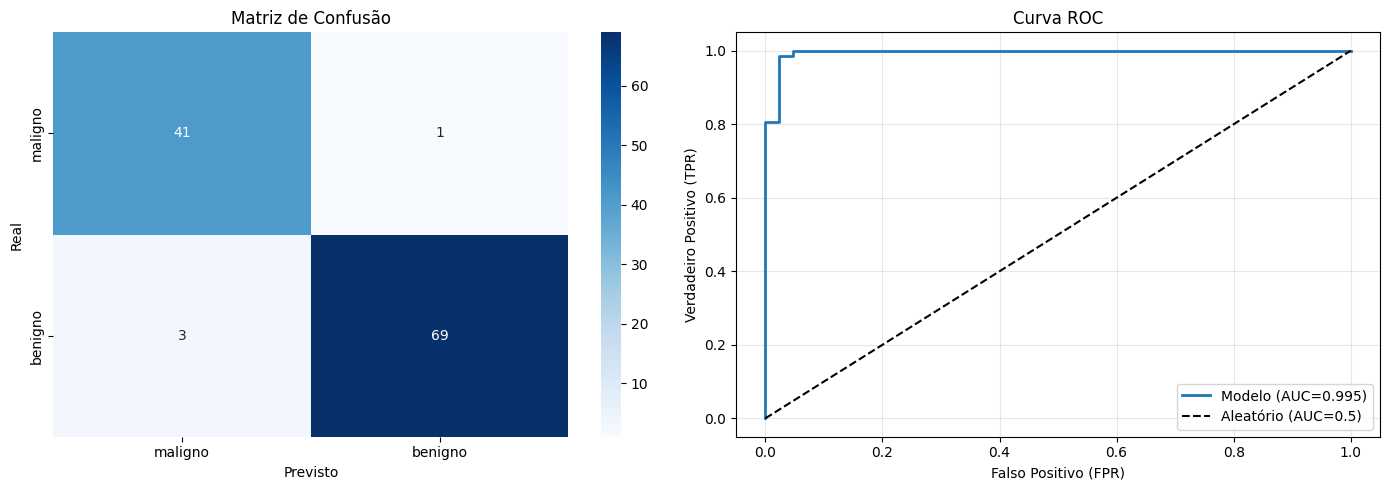

In [25]:
# =====================================================================
# 10. AVALIAÇÃO NO CONJUNTO DE TESTE
# =====================================================================
# Avaliamos o modelo REGULARIZADO (modelo_reg), que foi restaurado com os
# pesos da melhor época pelo early stopping.

modelo_reg.eval()
with torch.no_grad():
    logits_teste = modelo_reg(X_teste_t.to(device))
    # sigmoid converte logit -> probabilidade (0 a 1)
    probs = torch.sigmoid(logits_teste).cpu().numpy().flatten()
    previsoes = (probs >= 0.5).astype(int)   # limiar de decisão 0.5

y_true = y_teste.astype(int)

# --- Métricas principais ---
acuracia = accuracy_score(y_true, previsoes)
auc = roc_auc_score(y_true, probs)

print("=" * 55)
print("RESULTADOS FINAIS - MODELO REGULARIZADO")
print("=" * 55)
print(f"Acurácia       : {acuracia:.1%}")
print(f"AUC-ROC        : {auc:.3f}")
print(f"\n{classification_report(y_true, previsoes,target_names=['maligno', 'benigno'])}")

# --- Matriz de confusão ---
fig, eixos = plt.subplots(1, 2, figsize=(14, 5))
cm = confusion_matrix(y_true, previsoes)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=eixos[0],
            xticklabels=['maligno', 'benigno'],
            yticklabels=['maligno', 'benigno'])
eixos[0].set_xlabel('Previsto')
eixos[0].set_ylabel('Real')
eixos[0].set_title('Matriz de Confusão')

# --- Curva ROC ---
fpr, tpr, _ = roc_curve(y_true, probs)
eixos[1].plot(fpr, tpr, label=f'Modelo (AUC={auc:.3f})', linewidth=2)
eixos[1].plot([0, 1], [0, 1], 'k--', label='Aleatório (AUC=0.5)')
eixos[1].set_xlabel('Falso Positivo (FPR)')
eixos[1].set_ylabel('Verdadeiro Positivo (TPR)')
eixos[1].set_title('Curva ROC')
eixos[1].legend()
eixos[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Em contexto médico, FALSOS NEGATIVOS (dizer benigno quando é maligno)
# são os mais perigosos. Veja o recall da classe 'maligno' no report!

In [26]:
# =====================================================================
# 10.1 INTERPRETAÇÃO DINÂMICA DA AVALIAÇÃO
# =====================================================================
# Gera o markdown de interpretação com os valores reais desta execução.

# --- Extrai os componentes da matriz de confusão ---
# confusion_matrix com labels [0,1] = [maligno, benigno]
tn, fp, fn, tp = cm.ravel()

# --- Métricas derivadas ---
recall_maligno    = tn / (tn + fn) if (tn + fn) > 0 else 0
precisao_maligno  = tn / (tn + fp) if (tn + fp) > 0 else 0
f1_maligno        = (2 * precisao_maligno * recall_maligno /
                     (precisao_maligno + recall_maligno)
                     if (precisao_maligno + recall_maligno) > 0 else 0)

recall_benigno    = tp / (tp + fp) if (tp + fp) > 0 else 0
especificidade    = tp / (tp + fp) if (tp + fp) > 0 else 0

total_malignos    = tn + fn
total_benignos    = tp + fp
total_amostras    = total_malignos + total_benignos

# --- Avaliação da qualidade ---
if acuracia >= 0.97 and auc >= 0.99:
    veredito = "✅ **EXCELENTE** — desempenho no teto esperado para este dataset."
elif acuracia >= 0.95 and auc >= 0.98:
    veredito = "✅ **BOM** — dentro da faixa esperada (96–98% de acurácia)."
elif acuracia >= 0.90:
    veredito = "⚠️ **ACEITÁVEL** — abaixo do esperado para este problema."
else:
    veredito = "❌ **INSUFICIENTE** — investigar o pipeline antes de usar."

# --- Alerta de falsos negativos (o erro crítico em contexto médico) ---
if fn == 0:
    alerta_fn = ("✅ **Nenhum falso negativo** — todos os tumores malignos "
                 "foram identificados nesta amostra de teste.")
elif fn <= 2:
    alerta_fn = (f"⚠️ **{fn} falso(s) negativo(s)** — {fn} tumor(es) maligno(s) "
                 f"classificado(s) como benigno(s). Em contexto clínico, cada "
                 "um desses casos exigiria revisão manual.")
else:
    alerta_fn = (f"❌ **{fn} falsos negativos** — taxa de {fn/total_malignos:.1%} "
                 "dos malignos passou como benigno. Inaceitável em uso clínico "
                 "sem revisão humana obrigatória.")

# --- Alerta de vazamento (acurácia suspeita de tão alta) ---
if acuracia == 1.0 and auc == 1.0:
    alerta_vazamento = (
        "\n> ⚠️ **Atenção**: acurácia e AUC perfeitas (100%) são incomuns neste "
        "dataset, cuja EDA mostrou sobreposição entre as classes. Verifique se "
        "houve vazamento de dados (ex.: scaler ajustado no dataset inteiro).\n"
    )
else:
    alerta_vazamento = ""

relatorio = f"""
## 🔍 Interpretando a Avaliação

### Como ler a matriz de confusão

|  | Previsto maligno | Previsto benigno |
|---|---|---|
| **Real maligno** | {tn} (TN) | **{fn} (FN)** ⚠️ |
| **Real benigno** | **{fp} (FP)** | {tp} (TP) |

O erro mais grave em diagnóstico é o **falso negativo**: o modelo diz
"benigno" quando o tumor é maligno. O paciente vai para casa sem tratamento.

{alerta_fn}

### Métricas da classe crítica (maligno)

| Métrica | Valor | O que significa |
|---|---|---|
| **Recall** | **{recall_maligno:.1%}** | Dos {total_malignos} malignos reais, quantos foram detectados |
| **Precisão** | {precisao_maligno:.1%} | Dos previstos como malignos, quantos realmente eram |
| **F1-score** | {f1_maligno:.3f} | Equilíbrio entre recall e precisão |
| Especificidade | {especificidade:.1%} | Dos {total_benignos} benignos, quantos foram corretamente identificados |

👉 Em triagem médica, **recall alto é prioritário**: é melhor encaminhar um
benigno para biópsia (falso positivo) do que liberar um maligno.

### Desempenho geral

| Métrica | Valor |
|---|---|
| Acurácia | **{acuracia:.1%}** |
| AUC-ROC | **{auc:.3f}** |
| Amostras de teste | {total_amostras} |
| Malignos / Benignos | {total_malignos} / {total_benignos} |

{veredito}

### O que a AUC-ROC resume

A AUC mede a capacidade do modelo de **ordenar** corretamente: dado um caso
maligno e um benigno, qual a probabilidade de o modelo dar score maior ao
maligno? AUC = 1,0 é perfeito; 0,5 é chute aleatório. Neste modelo,
AUC = {auc:.3f} significa que em {auc:.1%} dos pares o maligno recebeu
score maior.
{alerta_vazamento}
### Expectativa realista

Dado o teto imposto pela sobreposição das classes vista na EDA, esperamos
**96–98% de acurácia** e **AUC acima de 0,99**. Um resultado muito abaixo
disso indicaria problema no pipeline — e 100% exigiria checar vazamento.
"""

display(Markdown(relatorio))


## 🔍 Interpretando a Avaliação

### Como ler a matriz de confusão

|  | Previsto maligno | Previsto benigno |
|---|---|---|
| **Real maligno** | 41 (TN) | **3 (FN)** ⚠️ |
| **Real benigno** | **1 (FP)** | 69 (TP) |

O erro mais grave em diagnóstico é o **falso negativo**: o modelo diz
"benigno" quando o tumor é maligno. O paciente vai para casa sem tratamento.

❌ **3 falsos negativos** — taxa de 6.8% dos malignos passou como benigno. Inaceitável em uso clínico sem revisão humana obrigatória.

### Métricas da classe crítica (maligno)

| Métrica | Valor | O que significa |
|---|---|---|
| **Recall** | **93.2%** | Dos 44 malignos reais, quantos foram detectados |
| **Precisão** | 97.6% | Dos previstos como malignos, quantos realmente eram |
| **F1-score** | 0.953 | Equilíbrio entre recall e precisão |
| Especificidade | 98.6% | Dos 70 benignos, quantos foram corretamente identificados |

👉 Em triagem médica, **recall alto é prioritário**: é melhor encaminhar um
benigno para biópsia (falso positivo) do que liberar um maligno.

### Desempenho geral

| Métrica | Valor |
|---|---|
| Acurácia | **96.5%** |
| AUC-ROC | **0.995** |
| Amostras de teste | 114 |
| Malignos / Benignos | 44 / 70 |

✅ **BOM** — dentro da faixa esperada (96–98% de acurácia).

### O que a AUC-ROC resume

A AUC mede a capacidade do modelo de **ordenar** corretamente: dado um caso
maligno e um benigno, qual a probabilidade de o modelo dar score maior ao
maligno? AUC = 1,0 é perfeito; 0,5 é chute aleatório. Neste modelo,
AUC = 0.995 significa que em 99.5% dos pares o maligno recebeu
score maior.

### Expectativa realista

Dado o teto imposto pela sobreposição das classes vista na EDA, esperamos
**96–98% de acurácia** e **AUC acima de 0,99**. Um resultado muito abaixo
disso indicaria problema no pipeline — e 100% exigiria checar vazamento.


## 💾 Salvando o Modelo para Produção

Um modelo treinado só é útil se puder ser **recarregado** depois. Mas salvar
apenas os pesos (`state_dict`) é um erro clássico: o modelo em produção
receberia dados **crus**, sem a padronização aplicada no treino, e as
previsões seriam completamente erradas.

O que precisa ir junto no arquivo:

| Item | Por quê |
|---|---|
| `state_dict` | Os pesos aprendidos |
| Nº de features | Recriar a arquitetura com a dimensão correta |
| `scaler.mean_` / `scaler.scale_` | Aplicar a mesma padronização em produção |
| Hiperparâmetros | Documentar a arquitetura (64/32, dropout) |
| Métricas de teste | Saber o desempenho esperado ao carregar |

⚠️ **Regra de ouro**: o que transformou os dados no treino precisa
transformar os dados em produção — exatamente igual.

In [27]:
# =====================================================================
# 11. RETREINO FINAL COM TODOS OS DADOS (antes de salvar)
# =====================================================================
# O modelo validado usou 80% dos dados. Para produção, retreinamos com
# 100%, mantendo os hiperparâmetros já validados.
#
# ⚠️ NÃO medimos métricas neste retreino: não há mais conjunto de teste
# independente. A métrica oficial é a da validação anterior.

# --- 1. Junta treino + teste e reajusta o scaler com todos os dados ---
X_todos = np.vstack([X_treino, X_teste])
y_todos = np.concatenate([y_treino, y_teste])

scaler_final = StandardScaler()
X_todos_pad = scaler_final.fit_transform(X_todos)   # agora aprende de TUDO

X_todos_t = torch.tensor(X_todos_pad, dtype=torch.float32)
y_todos_t = torch.tensor(y_todos, dtype=torch.float32).unsqueeze(1)

dataset_final = TensorDataset(X_todos_t, y_todos_t)
loader_final  = DataLoader(dataset_final, batch_size=BATCH_SIZE, shuffle=True)

print(f"Retreino final: {X_todos.shape[0]} amostras "
      f"({X_treino.shape[0]} treino + {X_teste.shape[0]} teste)")

# --- 2. Modelo novo, com a MESMA arquitetura validada ---
modelo_final = RedeNeuralRegularizada(
    n_entrada=X_todos.shape[1],
    n_oculta1=64,
    n_oculta2=32,
    dropout=0.3,
).to(device)

criterio_final = nn.BCEWithLogitsLoss()
otimizador_final = torch.optim.Adam(modelo_final.parameters(),
                                    lr=TAXA_APRENDIZADO,
                                    weight_decay=WEIGHT_DECAY)

# --- 3. Treina pelo número de épocas que o early stopping encontrou ---
# Usamos a melhor época da validação como orçamento de treino.
EPOCAS_FINAL = melhor_epoca   # ex.: 3 no seu caso

print(f"Treinando por {EPOCAS_FINAL} épocas "
      f"(mesmo orçamento que o early stopping escolheu)...\n")

modelo_final.train()
for epoca in range(1, EPOCAS_FINAL + 1):
    loss_acum = 0.0
    for X_batch, y_batch in loader_final:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        otimizador_final.zero_grad()
        logits = modelo_final(X_batch)
        loss = criterio_final(logits, y_batch)
        loss.backward()
        otimizador_final.step()

        loss_acum += loss.item() * X_batch.size(0)

    loss_epoca = loss_acum / len(dataset_final)
    print(f"Época {epoca:2d}/{EPOCAS_FINAL} | loss treino: {loss_epoca:.4f}")

modelo_final.eval()
print("\n✅ Retreino final concluído.")

Retreino final: 569 amostras (455 treino + 114 teste)
Treinando por 22 épocas (mesmo orçamento que o early stopping escolheu)...

Época  1/22 | loss treino: 0.6163
Época  2/22 | loss treino: 0.4487
Época  3/22 | loss treino: 0.2672
Época  4/22 | loss treino: 0.1593
Época  5/22 | loss treino: 0.1180
Época  6/22 | loss treino: 0.1014
Época  7/22 | loss treino: 0.0817
Época  8/22 | loss treino: 0.0720
Época  9/22 | loss treino: 0.0718
Época 10/22 | loss treino: 0.0658
Época 11/22 | loss treino: 0.0571
Época 12/22 | loss treino: 0.0610
Época 13/22 | loss treino: 0.0608
Época 14/22 | loss treino: 0.0549
Época 15/22 | loss treino: 0.0563
Época 16/22 | loss treino: 0.0516
Época 17/22 | loss treino: 0.0550
Época 18/22 | loss treino: 0.0491
Época 19/22 | loss treino: 0.0444
Época 20/22 | loss treino: 0.0494
Época 21/22 | loss treino: 0.0458
Época 22/22 | loss treino: 0.0448

✅ Retreino final concluído.


In [28]:
# =====================================================================
# 12. SALVANDO O MODELO FINAL PARA PRODUÇÃO
# =====================================================================


CAMINHO_MODELO = '../modelos/mama.pt'

checkpoint = {
    'state_dict': modelo_final.state_dict(),

    'arquitetura': {
        'n_entrada': X_todos.shape[1],
        'n_oculta1': 64,
        'n_oculta2': 32,
        'dropout': 0.3,
    },

    # Scaler reajustado com TODOS os dados
    'scaler': {
        'mean': scaler_final.mean_,
        'scale': scaler_final.scale_,
    },

    # Métricas da VALIDAÇÃO (não do retreino) - estimativa honesta
    'metricas_validacao': {
        'acuracia': float(acuracia),
        'auc': float(auc),
        'loss_teste': float(historico_reg['teste'][-1]),
        'melhor_epoca': int(melhor_epoca),
        'n_treino_validacao': int(X_treino.shape[0]),
        'n_teste_validacao': int(X_teste.shape[0]),
    },

    'treinamento_final': {
        'n_amostras': int(X_todos.shape[0]),
        'epocas': int(EPOCAS_FINAL),
        'nota': 'Retreinado com 100% dos dados após validação',
    },

    'treinado_em': datetime.now().isoformat(timespec='seconds'),
}

torch.save(checkpoint, CAMINHO_MODELO)

tamanho_kb = os.path.getsize(CAMINHO_MODELO) / 1024
print(f"✅ Modelo final salvo: {CAMINHO_MODELO} ({tamanho_kb:.1f} KB)")
print(f"   Amostras usadas: {checkpoint['treinamento_final']['n_amostras']}")
print(f"   Acurácia (validação): {acuracia:.1%}")
print(f"   AUC (validação): {auc:.3f}")

✅ Modelo final salvo: ../modelos/mama.pt (19.9 KB)
   Amostras usadas: 569
   Acurácia (validação): 96.5%
   AUC (validação): 0.995
